# Game recommendations with implicit-feedback ALS

Our outside-the-course method: matrix factorisation for implicit feedback (Hu, Koren & Volinsky, 2008), solved with alternating least squares. Each user and game gets a vector of `k` hidden factors, and their dot product scores how likely the user is to play the game. Playtime is used as *confidence* (`c = 1 + α·log(1 + minutes)`), not as a rating.

Outline:
1. Build the user × game matrix and hide games for validation and testing.
2. Tune the course-method baselines (association rules from frequent pairs, item–item similarity) and ALS on the validation set.
3. Compare all methods once on the test set.
4. Cross-check our ALS against the `implicit` library.
5. Inspect the learned game vectors: nearest neighbours, and k-means clusters compared with Steam tags.

## Data

Load the user inventories and keep games owned by at least 50 users (the same threshold as the Apriori/PCY baskets) and users with at least 5 played games. Owned-but-unplayed games count as not played.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from recommender import als, baselines, clusters, data, evaluate

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

user_items = data.load_user_items()
inter = data.build_interactions(user_items)

n_users, n_games = inter.playtime.shape
print(f"{n_users:,} users x {n_games:,} games, {inter.playtime.nnz:,} played pairs "
      f"({inter.playtime.nnz / (n_users * n_games):.2%} of the matrix filled)")

59,732 users x 5,198 games, 3,184,647 played pairs (1.03% of the matrix filled)


## Train / validation / test split

For every user, 20% of their played games are hidden as the **test** set. From the rest, another 20% are hidden as a **validation** set used for all tuning. Models are scored on how many hidden games appear in their top-10 recommendations (precision, recall, NDCG@10). *Coverage* is the share of all games recommended to at least one user.

In [2]:
train_full, test = data.split_per_user(inter.playtime, test_frac=0.2, seed=0)
train, valid = data.split_per_user(train_full, test_frac=0.2, seed=1)

print(f"train {train.nnz:,}  valid {valid.nnz:,}  test {test.nnz:,}")

def score(scorer, fit_on, truth):
    recs = evaluate.top_k(scorer, fit_on)
    metrics = evaluate.ranking_metrics(recs, truth)
    metrics.pop("users")
    return {**metrics, "coverage": evaluate.catalogue_coverage(recs, n_games)}

train 2,038,529  valid 509,535  test 636,583


## Course-method baselines on validation

- **Association rules.** Pair counts `BᵀB` (users who played both games) give exactly the frequent pairs that Apriori/PCY find for a given minimum support. A rule `i → j` has confidence P(played j | played i); a user's score for game `j` is their strongest rule into `j`.
- **Item–item similarity.** Cosine similarity between games' player sets, keeping each game's top-k neighbours; a user's score sums the similarity of `j` to every game they played.

In [3]:
counts = baselines.pair_counts(train)
rows = [{"method": "Popularity", "setting": "", **score(evaluate.popularity_scorer(train), train, valid)}]

for min_support in [10, 50, 200]:
    conf = baselines.rule_confidences(counts, min_support)
    rows.append({"method": "Association rules", "setting": f"min_support={min_support}",
                 **score(baselines.association_rule_scorer(train, conf), train, valid)})

for k in [20, 50, 200]:
    sim = baselines.cosine_neighbours(counts, k)
    rows.append({"method": "Item-item cosine", "setting": f"k={k}",
                 **score(baselines.item_knn_scorer(train, sim), train, valid)})

baseline_valid = pd.DataFrame(rows)
display(baseline_valid.round(4))

,method,setting,precision@10,recall@10,ndcg@10,coverage
0,Popularity,,0.1003,0.1730,0.1759,0.0071
1,Association rules,min_support=10,0.1341,0.2331,0.2339,0.1881
2,Association rules,min_support=50,0.1372,0.2353,0.2383,0.0779
3,Association rules,min_support=200,0.1360,0.2335,0.2371,0.0371
4,Item-item cosine,k=20,0.1208,0.2084,0.2067,0.2072
5,Item-item cosine,k=50,0.1161,0.2008,0.2031,0.1701
6,Item-item cosine,k=200,0.1200,0.2111,0.2116,0.1643


## Tuning ALS on validation

Grid over the number of factors, regularisation λ, the confidence scale α, and an optional **idf weighting** that multiplies each game's playtime term by `log(users / players)`, so plays of niche games count for more than plays of games everyone has. A first exploration showed that λ ≤ 10 overfits badly (more factors made results worse), so the grid starts at λ = 100.

In [4]:
ITERATIONS = 15
idf = als.idf_weights(train)

rows = []
for weighting in ["none", "idf"]:
    for alpha in [3.0, 10.0]:
        conf = als.confidence(train, alpha, idf if weighting == "idf" else None)
        for factors in [64, 128]:
            for reg in [100.0, 300.0, 1000.0]:
                model = als.fit(conf, factors, reg, ITERATIONS)
                rows.append({"weighting": weighting, "alpha": alpha, "factors": factors, "reg": reg,
                             **score(evaluate.als_scorer(model), train, valid)})

als_grid = pd.DataFrame(rows).sort_values("ndcg@10", ascending=False, ignore_index=True)
display(als_grid.head(10).round(4))

,weighting,alpha,factors,reg,precision@10,recall@10,ndcg@10,coverage
0,none,3.0,128,300.0,0.1464,0.2506,0.2444,0.1458
1,idf,3.0,128,300.0,0.1440,0.2428,0.2422,0.1208
2,idf,3.0,64,300.0,0.1437,0.2423,0.2415,0.1199
3,idf,10.0,128,300.0,0.1410,0.2478,0.2370,0.2849
4,none,3.0,64,300.0,0.1393,0.2381,0.2302,0.1304
5,idf,3.0,64,100.0,0.1359,0.2339,0.2273,0.2043
6,idf,10.0,64,300.0,0.1360,0.2392,0.2265,0.2622
7,none,10.0,128,1000.0,0.1331,0.2272,0.2226,0.1220
8,none,10.0,64,1000.0,0.1329,0.2269,0.2223,0.1218
9,idf,10.0,128,1000.0,0.1274,0.2167,0.2168,0.0883


Accuracy against coverage for every configuration. Points further up recommend the hidden games better; points further right recommend a wider range of games instead of the same hits to everyone.

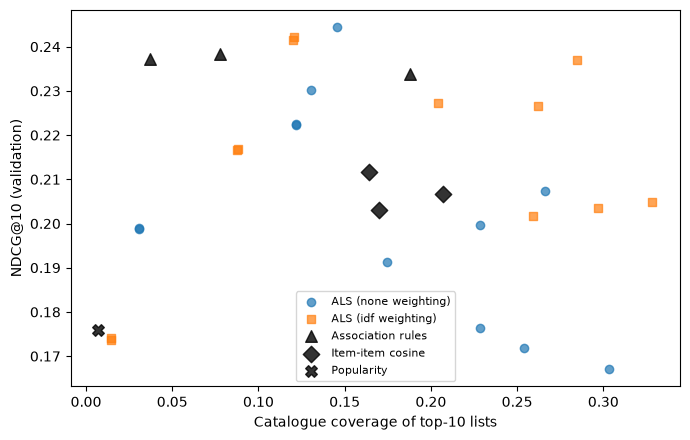

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for weighting, marker in [("none", "o"), ("idf", "s")]:
    part = als_grid[als_grid["weighting"] == weighting]
    ax.scatter(part["coverage"], part["ndcg@10"], marker=marker, alpha=0.7, label=f"ALS ({weighting} weighting)")
for (method, part), marker in zip(baseline_valid.groupby("method"), ["^", "D", "X"]):
    ax.scatter(part["coverage"], part["ndcg@10"], marker=marker, s=70, color="black", alpha=0.8, label=method)
ax.set_xlabel("Catalogue coverage of top-10 lists")
ax.set_ylabel("NDCG@10 (validation)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "ndcg_vs_coverage.pdf")
plt.show()

## Final comparison on the test set

Each method uses its best validation setting (by NDCG@10), is refitted on train + validation, and is scored once on the test games. We also keep the best **idf-weighted** ALS, to see whether down-weighting popular games changes the results.

In [6]:
best_rules = baseline_valid[baseline_valid["method"] == "Association rules"].nlargest(1, "ndcg@10").iloc[0]
best_knn = baseline_valid[baseline_valid["method"] == "Item-item cosine"].nlargest(1, "ndcg@10").iloc[0]
best_als = als_grid.iloc[0]
best_als_idf = als_grid[als_grid["weighting"] == "idf"].iloc[0]
print("Chosen:", best_rules["setting"], "|", best_knn["setting"], "|",
      dict(best_als[["weighting", "alpha", "factors", "reg"]]), "|",
      dict(best_als_idf[["weighting", "alpha", "factors", "reg"]]))

def fit_als(cfg, playtime):
    weights = als.idf_weights(playtime) if cfg["weighting"] == "idf" else None
    start = time.perf_counter()
    model = als.fit(als.confidence(playtime, cfg["alpha"], weights), int(cfg["factors"]), cfg["reg"], ITERATIONS)
    return model, time.perf_counter() - start

counts_full = baselines.pair_counts(train_full)
min_support = int(best_rules["setting"].split("=")[1])
knn_k = int(best_knn["setting"].split("=")[1])
model, fit_seconds = fit_als(best_als, train_full)
model_idf, fit_seconds_idf = fit_als(best_als_idf, train_full)

final = {
    "Popularity": evaluate.popularity_scorer(train_full),
    f"Association rules ({best_rules['setting']})":
        baselines.association_rule_scorer(train_full, baselines.rule_confidences(counts_full, min_support)),
    f"Item-item cosine ({best_knn['setting']})":
        baselines.item_knn_scorer(train_full, baselines.cosine_neighbours(counts_full, knn_k)),
    "ALS": evaluate.als_scorer(model),
    "ALS + idf weighting": evaluate.als_scorer(model_idf),
}
test_results = pd.DataFrame(
    [{"method": name, **score(scorer, train_full, test)} for name, scorer in final.items()]
).set_index("method")

print(f"ALS fit: {fit_seconds:.1f} s, ALS + idf fit: {fit_seconds_idf:.1f} s ({ITERATIONS} sweeps)")
test_results.round(4).to_csv(FIGURES / "test_results.csv")
display(test_results.round(3))

Chosen: min_support=50 | k=200 | {'weighting': 'none', 'alpha': np.float64(3.0), 'factors': np.int64(128), 'reg': np.float64(300.0)} | {'weighting': 'idf', 'alpha': np.float64(3.0), 'factors': np.int64(128), 'reg': np.float64(300.0)}


ALS fit: 14.9 s, ALS + idf fit: 14.8 s (15 sweeps)


,precision@10,recall@10,ndcg@10,coverage
method,,,,
Popularity,0.135,0.180,0.220,0.010
Association rules (min_support=50),0.197,0.256,0.321,0.101
Item-item cosine (k=200),0.165,0.222,0.271,0.140
ALS,0.217,0.282,0.337,0.168
ALS + idf weighting,0.211,0.269,0.329,0.153


## Cross-check against the `implicit` library

`implicit` implements the same paper. With the same confidence values and settings (the chosen unweighted ALS), its scores should match ours. We use its exact (Cholesky) solver, not its default conjugate-gradient approximation.

In [7]:
from implicit.cpu.als import AlternatingLeastSquares

log_playtime = train_full.copy()
log_playtime.data = np.log1p(log_playtime.data)  # implicit uses c = 1 + alpha * value

lib = AlternatingLeastSquares(
    factors=int(best_als["factors"]), regularization=best_als["reg"], alpha=best_als["alpha"],
    iterations=ITERATIONS, use_cg=False, random_state=0,
)
start = time.perf_counter()
lib.fit(log_playtime, show_progress=False)
lib_seconds = time.perf_counter() - start

lib_model = als.ALSModel(np.asarray(lib.user_factors), np.asarray(lib.item_factors))
print(f"implicit fit: {lib_seconds:.1f} s vs ours {fit_seconds:.1f} s")
display(pd.DataFrame({
    "ours": test_results.loc["ALS"],
    "implicit": pd.Series(score(evaluate.als_scorer(lib_model), train_full, test)),
}).round(3))

implicit fit: 114.6 s vs ours 14.9 s


,ours,implicit
precision@10,0.217,0.218
recall@10,0.282,0.282
ndcg@10,0.337,0.338
coverage,0.168,0.162


## Similar games

Games with similar vectors are played by the same kind of users. We compare the neighbours from plain ALS and the idf-weighted version for a very popular game and a few niche ones.

In [8]:
name_to_index = {inter.item_names[item_id]: i for i, item_id in enumerate(inter.item_ids)}

def show_similar(title, n=8):
    columns = {}
    for label, m in [("ALS", model), ("ALS + idf", model_idf)]:
        top, _ = als.similar_items(m, name_to_index[title], n)
        columns[label] = [inter.item_names[inter.item_ids[i]] for i in top]
    return pd.DataFrame(columns).rename_axis(f"Similar to {title}")

for title in ["Counter-Strike: Global Offensive", "Sid Meier's Civilization V",
              "Euro Truck Simulator 2", "Dark Souls: Prepare to Die Edition"]:
    display(show_similar(title))

,ALS,ALS + idf
Similar to Counter-Strike: Global Offensive,,
0,Garry's Mod,Garry's Mod
1,Left 4 Dead 2,Left 4 Dead 2
2,Unturned,PAYDAY 2
3,Counter-Strike: Source,Unturned
4,PAYDAY 2,Terraria
5,Terraria,Counter-Strike: Source
6,Portal 2,Portal 2
7,Warframe,Warframe


,ALS,ALS + idf
Similar to Sid Meier's Civilization V,,
0,Sid Meier's Civilization: Beyond Earth,FTL: Faster Than Light
1,FTL: Faster Than Light,XCOM: Enemy Unknown
2,XCOM: Enemy Unknown,The Elder Scrolls V: Skyrim
3,Cities: Skylines,Age of Empires II: HD Edition
4,Banished,Sid Meier's Civilization: Beyond Earth
5,Guns of Icarus Online,Prison Architect
6,Age of Empires II: HD Edition,Chivalry: Medieval Warfare
7,Total War: SHOGUN 2,Cities: Skylines


,ALS,ALS + idf
Similar to Euro Truck Simulator 2,,
0,Bus Driver,Bus Driver
1,Scania Truck Driving Simulator,Microsoft Flight Simulator X: Steam Edition
2,OMSI 2,Scania Truck Driving Simulator
3,American Truck Simulator,Car Mechanic Simulator 2014
4,Microsoft Flight Simulator X: Steam Edition,American Truck Simulator
5,Trucks & Trailers,Euro Truck Simulator
6,Spintires,OMSI 2
7,Train Simulator,Spintires


,ALS,ALS + idf
Similar to Dark Souls: Prepare to Die Edition,,
0,DARK SOULS™ II,DARK SOULS™ II
1,DARK SOULS™ II: Scholar of the First Sin,DARK SOULS™ II: Scholar of the First Sin
2,DARK SOULS III,DARK SOULS III
3,The Witcher 2: Assassins of Kings Enhanced Edi...,The Witcher 2: Assassins of Kings Enhanced Edi...
4,Dragon's Dogma: Dark Arisen,The Witcher: Enhanced Edition
5,Dragon Age: Origins - Ultimate Edition,Dragon Age: Origins - Ultimate Edition
6,Rogue Legacy,Fallout 3 - Game of the Year Edition
7,The Witcher: Enhanced Edition,Fallout: New Vegas


## Clustering the game vectors (k-means)

If the factors capture taste, games should group by genre even though ALS never saw any tags. We run k-means on the idf-weighted model's game vectors, scaled to unit length so games group by *direction* (taste) rather than vector length (popularity), and choose k with the Davies–Bouldin index (lower is better). We then compare the clusters with Steam's user tags, which ALS never saw.

4,412 of 5,198 games have Steam tags


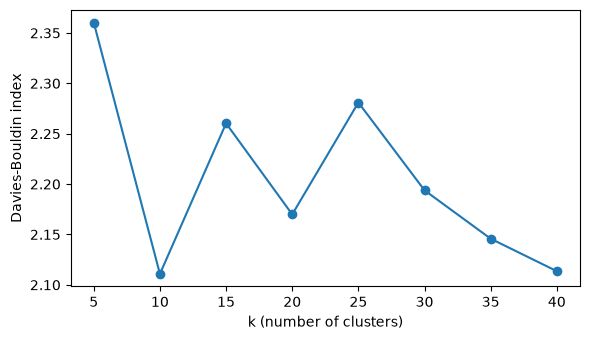

Lowest Davies-Bouldin index at k = 10


In [9]:
game_tags = clusters.load_game_tags()
tagged = np.array([item_id in game_tags for item_id in inter.item_ids])
tag_lists = [game_tags[item_id] for item_id in inter.item_ids[tagged]]
vectors = clusters.unit_rows(model_idf.item_factors[tagged])
print(f"{tagged.sum():,} of {n_games:,} games have Steam tags")

db_scores, labels_by_k = clusters.kmeans_sweep(vectors, ks=range(5, 41, 5))
best_k = int(db_scores.loc[db_scores["davies_bouldin"].idxmin(), "k"])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(db_scores["k"], db_scores["davies_bouldin"], marker="o")
ax.set_xlabel("k (number of clusters)")
ax.set_ylabel("Davies-Bouldin index")
fig.tight_layout()
fig.savefig(FIGURES / "davies_bouldin.pdf")
plt.show()
print(f"Lowest Davies-Bouldin index at k = {best_k}")

The most over-represented tags in each cluster (lift = how much more common the tag is in the cluster than among all games), and the normalised mutual information (NMI) between clusters and each game's most-voted tag, compared with the same clusters randomly shuffled.

In [10]:
labels = labels_by_k[best_k]
nmi, nmi_shuffled = clusters.nmi_with_top_tag(labels, tag_lists)
print(f"NMI with top tag: {nmi:.3f} (shuffled clusters: {nmi_shuffled:.3f})")

lift_table = clusters.tag_lift(labels, tag_lists)
with pd.option_context("display.max_colwidth", None):
    display(lift_table)

NMI with top tag: 0.280 (shuffled clusters: 0.047)


,cluster,games,top tags (lift)
0,1,935,"Otome (2.7), Hidden Object (2.5), Vampire (1.9), Shoot 'Em Up (1.8), Point & Click (1.7)"
1,8,552,"Warhammer 40K (8.0), 4X (7.6), Diplomacy (7.3), Grand Strategy (7.0), Real Time Tactics (7.0)"
2,6,504,"Match 3 (4.5), Touch-Friendly (2.6), Top-Down Shooter (2.5), Conspiracy (2.4), Detective (2.3)"
3,9,475,"Batman (7.9), LEGO (7.8), Assassin (6.8), Comic Book (5.7), Team-Based (5.6)"
4,5,460,"Programming (7.2), Abstract (5.5), GameMaker (5.3), Rogue-lite (5.1), Minimalist (4.8)"
5,7,413,"MMORPG (8.2), Gambling (7.6), Free to Play (7.5), Massively Multiplayer (7.2), Clicker (6.8)"
6,0,401,"RPGMaker (4.3), Shoot 'Em Up (3.4), Illuminati (1.9), Puzzle-Platformer (1.6), Retro (1.6)"
7,4,321,"Lara Croft (9.5), Inventory Management (8.2), Silent Protagonist (6.9), Bullet Time (6.6), Star Wars (6.0)"
8,3,179,"Spectacle fighter (14.3), Dating Sim (12.9), Character Action Game (12.3), JRPG (12.1), Romance (11.2)"
9,2,172,"Offroad (21.4), Driving (18.4), TrackIR (15.7), Trains (13.7), Agriculture (12.0)"


## Notes for the report

- Strong regularisation is essential on this data: with small λ, more factors overfit and do worse.
- Compare ALS with association rules on both accuracy and coverage. At its most accurate setting (α = 3) the idf weighting did not widen coverage; with α = 10 it roughly doubled coverage (see the scatter plot) for about 0.007 lower validation NDCG.
- Figures for Overleaf are written to `figures/`.